# Task 2 — Player Segment Classification: EDA

**Goal:** classify players into 0=Casual, 1=Grinder, 2=Social, 3=Whale. **Metric:** macro F1.

Sections
1. Load & overview
2. Target distribution
3. Missing values (and whether missingness carries signal)
4. Data quality: ranges, impossible values, duplicates
5. Numeric features by segment
6. Categorical features by segment
7. Correlations
8. Feature signal ranking (mutual information)
9. Train vs test drift (adversarial validation)
10. Summary of findings → next steps

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from data import (load_train, load_test, numeric_cols, CAT_COLS, NOISE_COLS,
                  TARGET, ID_COL, CLASS_NAMES, FIG_DIR, SEED)

FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 60, "display.width", 200)
sns.set_theme(style="whitegrid")
PALETTE = {"Casual": "#4C72B0", "Grinder": "#DD8452", "Social": "#55A868", "Whale": "#C44E52"}

## 1. Load & overview

In [2]:
train, test = load_train(), load_test()
NUM = numeric_cols(train)
train["seg_name"] = train[TARGET].map(CLASS_NAMES)
print("train:", train.shape, " test:", test.shape)
print(f"numeric: {len(NUM)}  categorical: {len(CAT_COLS)}")
train.head()

train: (104000, 47)  test: (25889, 45)
numeric: 34  categorical: 10


,player_id,play_frequency,avg_session_duration,total_playtime_hours,login_streak,days_since_last_login,total_spending_thb,avg_monthly_spending,spending_frequency,friend_count,team_play_percentage,chat_activity_score,friend_invites_sent,gifts_sent_received,ranked_participation_rate,tournament_entries,competitive_rank,win_rate_ranked,watches_esports,achievement_completion_rate,collection_progress,rare_items_count,speed_of_progression,item_type_preference_cosmetic,item_type_preference_performance,item_type_preference_social,account_age_days,vip_tier,responds_to_discounts,preferred_game_mode,avg_match_length,peak_concurrent_hours,random_metric_1,random_metric_2,random_metric_3,region,platform,device_type,payment_method,language,account_status,player_type_tag,engagement_level,loyalty_tier,skill_tier,segment,seg_name
0,P129924,5.166703,83.956912,1784.862304,80.0,94.345964,540.168064,6404.765652,24.400908,6.0,41.734606,176.811330,24.0,26.0,NaN,31.0,0.0,34.310303,0.0,53.958762,32.553226,37.0,6.747310,0.468860,0.679516,0.388402,221.0,0.0,NaN,4.0,33.066313,71.861478,524.015046,0.572867,NaN,AS,NaN,Laptop,Card,NaN,Dormant,Casual,Low,Silver,Silver,2,Social
1,P061398,2.363935,26.686070,4180.785530,91.0,97.429341,26997.309328,NaN,20.242690,32.0,35.429745,9.636806,54.0,50.0,61.372934,6.0,8.0,48.054808,1.0,24.131236,10.000000,12.0,5.425249,0.706480,0.207761,0.336906,1300.0,4.0,0.0,4.0,37.100925,79.899206,29.527728,0.596731,76.0,EU,Mobile,Tablet,NaN,FR,Dormant,Casual,Mid,Platinum,Bronze,3,Whale
2,P023935,34.709108,122.504325,1382.249476,106.0,4.009090,62175.578032,2284.189836,10.729244,33.0,62.835487,39.381016,61.0,76.0,81.837417,24.0,0.0,34.339921,1.0,64.266613,43.121336,95.0,10.994563,0.646164,0.155593,0.590148,356.0,1.0,0.0,3.0,77.078711,128.341446,921.762406,0.546043,NaN,EU,PC,Laptop,NaN,DE,Dormant,Competitive,High,Platinum,Diamond,3,Whale
3,P091426,11.304823,174.052106,2544.019165,43.0,NaN,28710.877472,NaN,25.437711,122.0,88.400486,186.528976,63.0,220.0,89.167947,32.0,6.0,48.016151,0.0,21.445670,45.011601,84.0,3.042915,NaN,0.783869,0.713969,NaN,0.0,1.0,2.0,27.496727,85.441221,273.290572,0.468750,147.0,APAC,Mobile,Laptop,Gift,FR,Dormant,Casual,High,Silver,Silver,1,Grinder
4,P058826,24.997414,61.008515,3285.259530,82.0,25.814744,33666.539627,1600.569528,10.450822,151.0,70.615073,46.484060,NaN,75.0,0.000000,57.0,4.0,NaN,0.0,74.296990,31.167845,11.0,11.295772,0.879529,NaN,0.569277,NaN,NaN,1.0,1.0,NaN,66.709668,650.630578,0.434456,79.0,AS,Console,Tablet,NaN,KR,Active,Competitive,High,Gold,Diamond,1,Grinder


In [3]:
train.dtypes.value_counts()

float64    34
str        12
int64       1
Name: count, dtype: int64

## 2. Target distribution

,count,share
seg_name,,
Casual,40957,0.394
Grinder,26032,0.250
Social,21029,0.202
Whale,15982,0.154


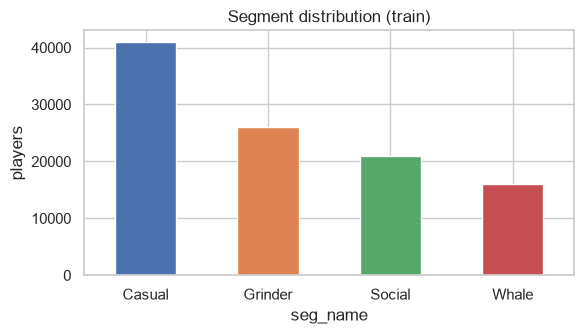

In [4]:
vc = train["seg_name"].value_counts().reindex(CLASS_NAMES.values())
display(pd.DataFrame({"count": vc, "share": (vc / len(train)).round(3)}))
ax = vc.plot.bar(color=[PALETTE[k] for k in vc.index], figsize=(6, 3.5), rot=0)
ax.set_title("Segment distribution (train)"); ax.set_ylabel("players")
plt.tight_layout(); plt.savefig(FIG_DIR / "target_distribution.png", dpi=120); plt.show()

Macro F1 weights each class equally, so the minority class (Whale) matters as much as Casual.

## 3. Missing values

In [5]:
miss = pd.DataFrame({
    "train_%": train.drop(columns=["seg_name"]).isna().mean() * 100,
    "test_%": test.isna().mean() * 100,
}).round(2).sort_values("train_%", ascending=False)
display(miss[miss["train_%"] > 0])
print("rows with >=1 missing:", f"{train.isna().any(axis=1).mean():.1%}")
print("missing cells per row:"); print(train[NUM + CAT_COLS].isna().sum(axis=1).describe().round(2))

,train_%,test_%
payment_method,30.82,30.40
region,26.18,26.09
engagement_level,7.85,7.74
team_play_percentage,7.83,7.57
platform,7.81,7.55
random_metric_2,7.81,7.71
ranked_participation_rate,7.78,7.88
avg_monthly_spending,7.77,7.62
tournament_entries,7.74,7.74
chat_activity_score,7.73,7.61


rows with >=1 missing: 98.2%
missing cells per row:
count    104000.00
mean          3.80
std           1.84
min           0.00
25%           2.00
50%           4.00
75%           5.00
max          13.00
dtype: float64


### Does missingness depend on segment? (if yes → add missing-indicator features)

In [6]:
miss_by_seg = (train[NUM + CAT_COLS].isna()
               .groupby(train["seg_name"]).mean().T * 100).round(2)
miss_by_seg = miss_by_seg[list(CLASS_NAMES.values())]
miss_by_seg["spread"] = miss_by_seg.max(axis=1) - miss_by_seg.min(axis=1)
display(miss_by_seg.sort_values("spread", ascending=False).head(15))

seg_name,Casual,Grinder,Social,Whale,spread
region,26.47,26.23,25.71,25.96,0.76
random_metric_1,7.81,7.71,7.55,7.13,0.68
avg_session_duration,7.61,8.08,7.58,7.44,0.64
collection_progress,7.56,7.50,7.90,8.12,0.62
peak_concurrent_hours,7.62,7.85,7.48,8.10,0.62
responds_to_discounts,7.78,7.87,7.69,7.36,0.51
payment_method,30.88,30.79,30.57,31.08,0.51
total_spending_thb,7.67,7.91,7.44,7.50,0.47
random_metric_2,7.64,8.08,7.78,7.82,0.44
account_age_days,7.71,7.47,7.56,7.91,0.44


## 4. Data quality

In [7]:
desc = train[NUM].describe(percentiles=[.01, .5, .99]).T
desc["n_negative"] = (train[NUM] < 0).sum()
desc["n_unique"] = train[NUM].nunique()
display(desc.round(3))

,count,mean,std,min,1%,50%,99%,max,n_negative,n_unique
play_frequency,95977.0,12.139,7.081,1.000,1.222,11.414,30.465,45.103,0,95977
avg_session_duration,95999.0,107.530,54.147,20.001,21.848,102.860,246.197,384.269,0,95999
total_playtime_hours,95993.0,1704.786,944.942,100.004,138.482,1643.098,4064.558,6019.906,0,95993
login_streak,96044.0,55.069,35.312,0.000,1.000,52.000,147.000,244.000,0,209
days_since_last_login,95995.0,45.937,20.801,0.000,2.681,45.754,94.949,132.869,0,95995
total_spending_thb,96035.0,34323.517,22145.758,501.186,1169.102,31691.384,92789.528,142934.433,0,96035
avg_monthly_spending,95919.0,3305.152,1936.702,100.142,170.190,3155.140,8258.157,12555.758,0,95919
spending_frequency,96033.0,16.983,9.655,1.000,1.388,16.217,41.488,63.914,0,96033
friend_count,95996.0,107.452,64.842,0.000,2.000,103.000,272.000,428.000,0,369
team_play_percentage,95857.0,50.344,19.704,5.000,5.000,50.288,96.805,100.000,0,94128


In [8]:
# Domain sanity checks
checks = {
    "play_frequency > 7 (days/week)": (train["play_frequency"] > 7).sum(),
    "percentage cols > 100": sum((train[c] > 100).sum() for c in
        ["team_play_percentage", "ranked_participation_rate", "win_rate_ranked",
         "achievement_completion_rate", "collection_progress"]),
    "negative spending": (train[["total_spending_thb", "avg_monthly_spending"]] < 0).sum().sum(),
    "avg_session_duration > 24h": (train["avg_session_duration"] > 1440).sum(),
    "peak_concurrent_hours > 24": (train["peak_concurrent_hours"] > 24).sum(),
}
display(pd.Series(checks, name="rows"))

play_frequency > 7 (days/week)    69375
percentage cols > 100                 0
negative spending                     0
avg_session_duration > 24h            0
peak_concurrent_hours > 24        74820
Name: rows, dtype: int64

In [9]:
print("duplicate player_id in train:", train[ID_COL].duplicated().sum())
print("duplicate feature rows in train:", train.drop(columns=[ID_COL]).duplicated().sum())
print("player_id overlap train/test:", len(set(train[ID_COL]) & set(test[ID_COL])))
print("low-cardinality numeric cols (<=12 unique, probably ordinal/binary):")
print({c: sorted(train[c].dropna().unique().tolist()) for c in NUM if train[c].nunique() <= 12})

duplicate player_id in train: 0


duplicate feature rows in train: 0
player_id overlap train/test: 0
low-cardinality numeric cols (<=12 unique, probably ordinal/binary):


{'competitive_rank': [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0], 'watches_esports': [0.0, 1.0], 'vip_tier': [0.0, 1.0, 2.0, 3.0, 4.0, 5.0], 'responds_to_discounts': [0.0, 1.0], 'preferred_game_mode': [0.0, 1.0, 2.0, 3.0, 4.0]}


## 5. Numeric features by segment

In [10]:
med = train.groupby("seg_name")[NUM].median().T[list(CLASS_NAMES.values())]
# ratio of max/min class median -> crude separability indicator
med["max/min"] = (med.max(axis=1) / med.min(axis=1).replace(0, np.nan)).round(2)
display(med.round(2).sort_values("max/min", ascending=False))

seg_name,Casual,Grinder,Social,Whale,max/min
avg_monthly_spending,2564.96,2841.57,3797.57,4525.63,1.76
spending_frequency,13.18,14.62,19.50,23.15,1.76
rare_items_count,66.00,74.00,99.00,116.00,1.76
total_spending_thb,26139.27,28611.49,38179.36,45092.71,1.73
friend_invites_sent,34.00,49.00,36.00,51.00,1.50
friend_count,87.00,123.00,90.00,126.00,1.45
total_playtime_hours,1388.67,1976.76,1469.98,2015.05,1.45
tournament_entries,22.00,31.00,23.00,32.00,1.45
speed_of_progression,4.41,6.24,4.63,6.41,1.45
peak_concurrent_hours,44.33,61.51,46.46,64.06,1.45


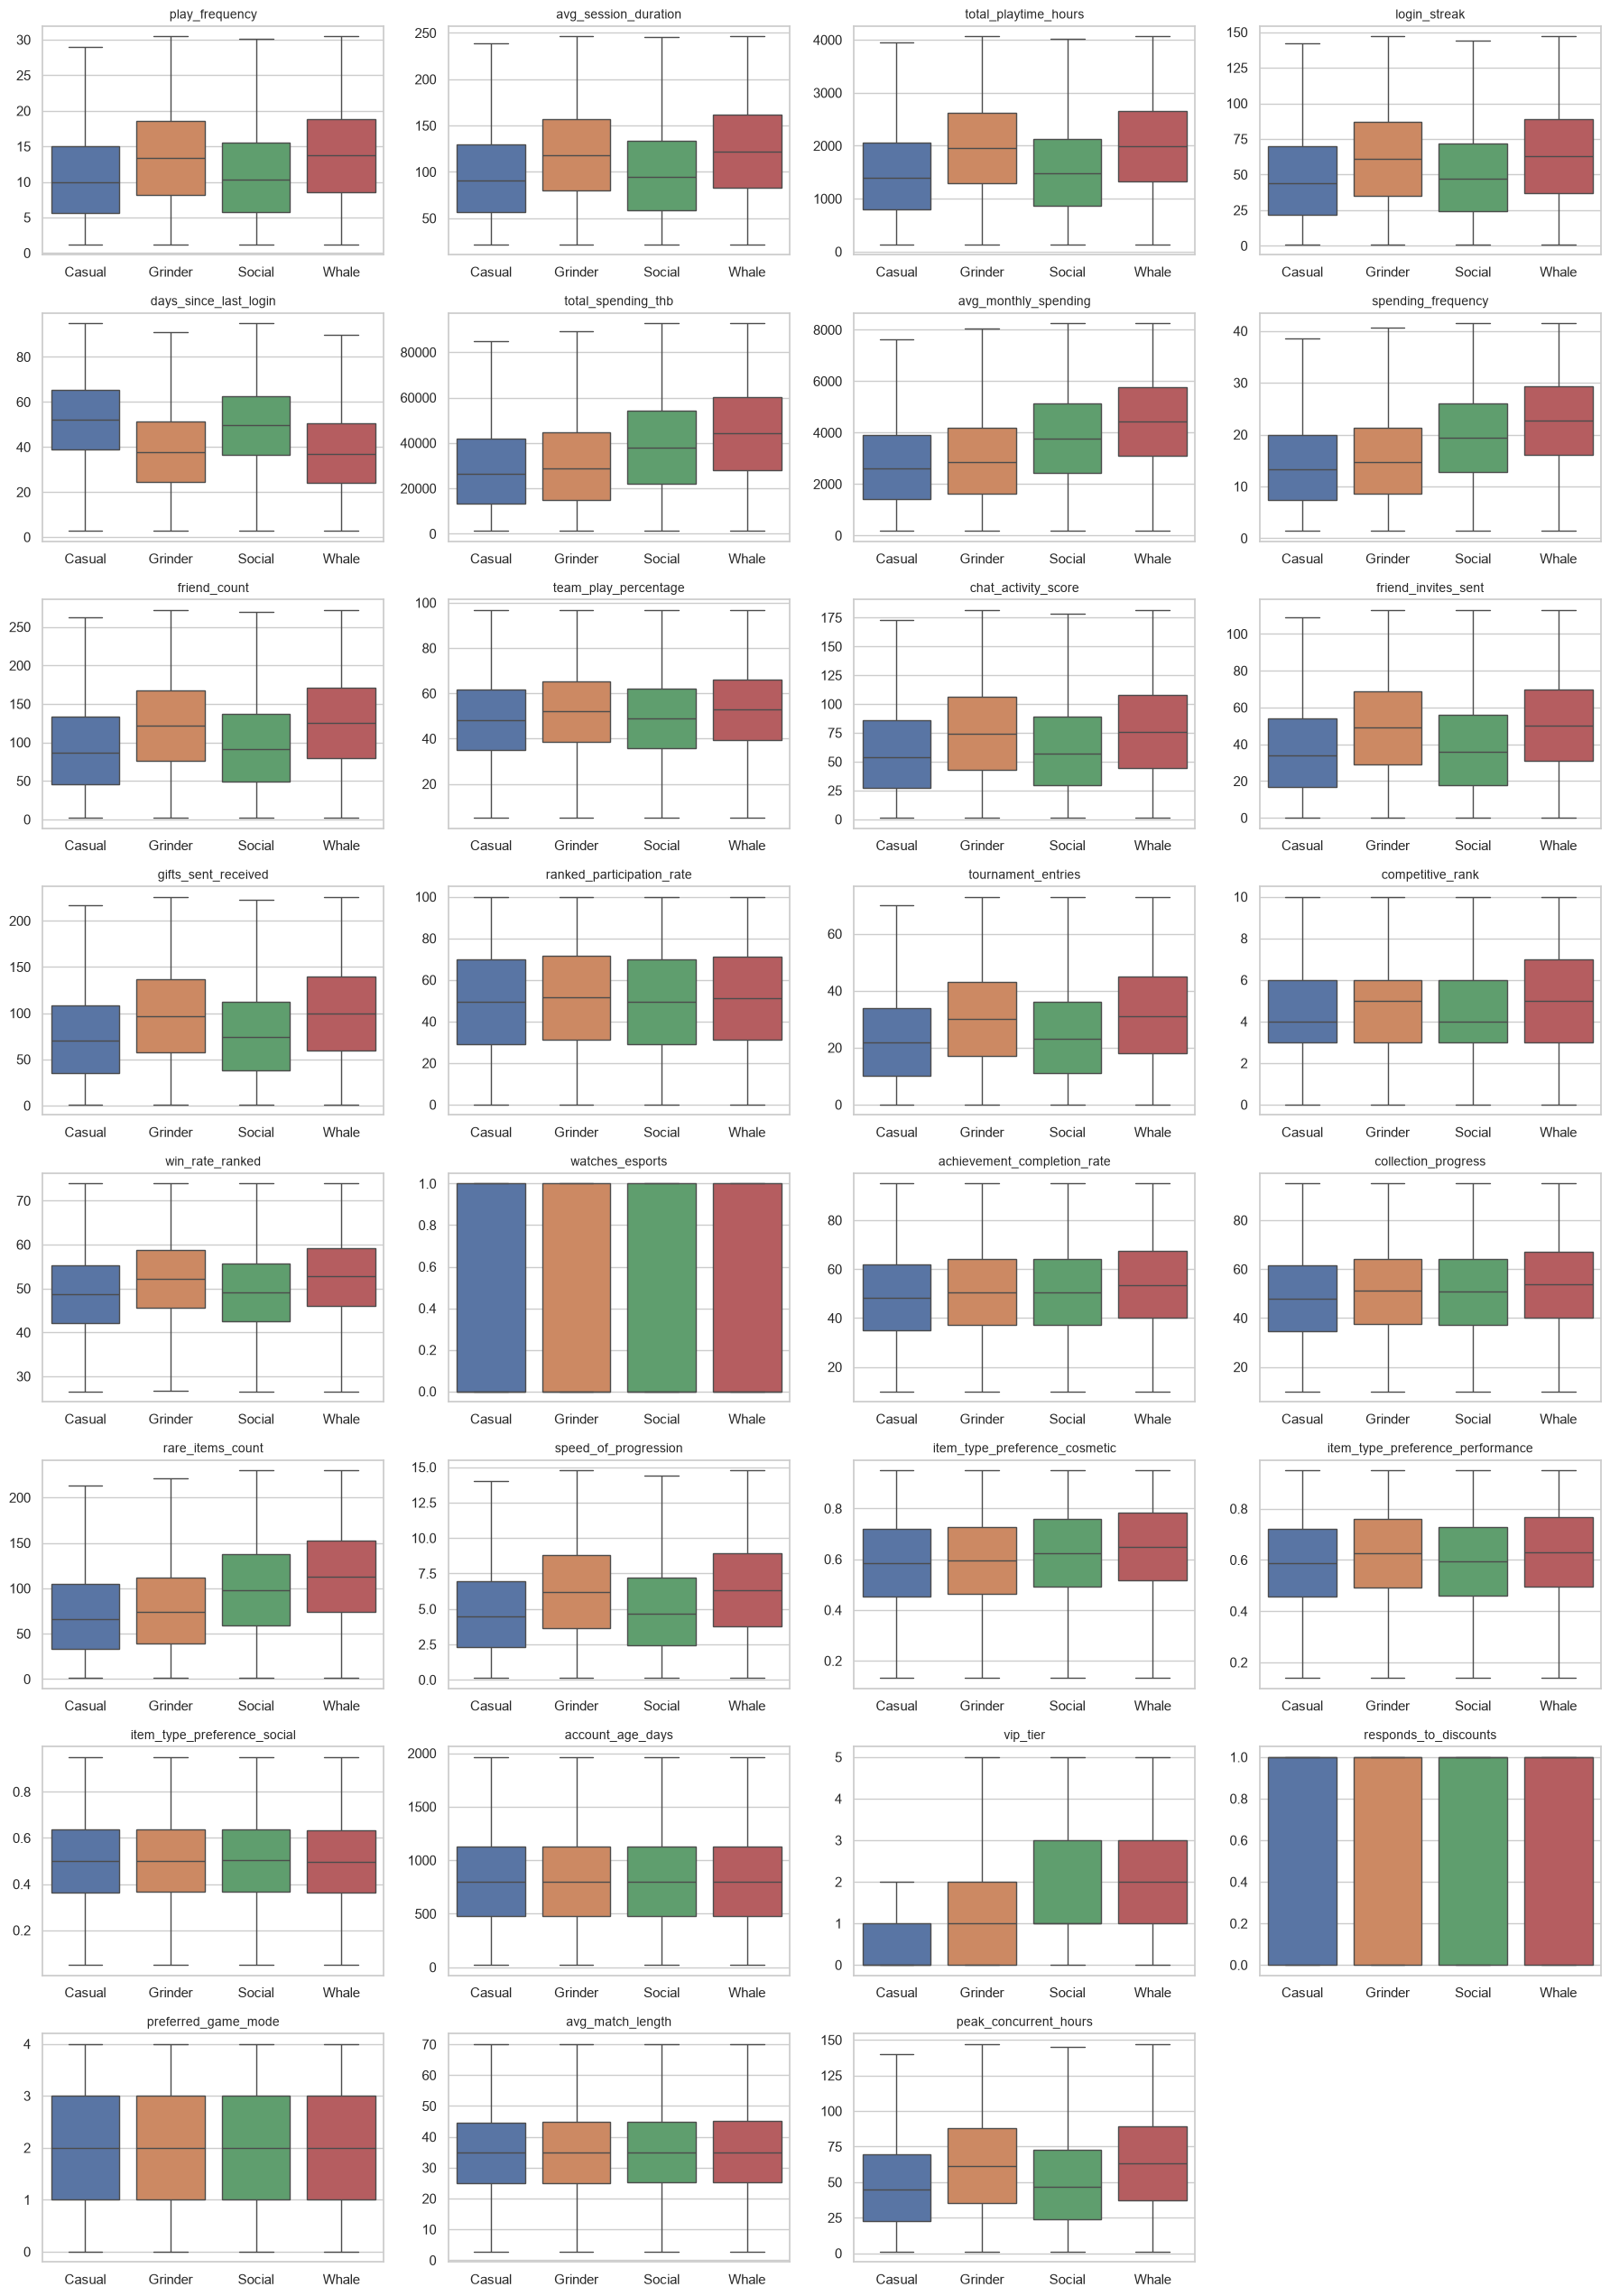

In [11]:
cols = [c for c in NUM if c not in NOISE_COLS]
n = len(cols); ncol = 4; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(18, 3.2 * nrow))
order = list(CLASS_NAMES.values())
for ax, c in zip(axes.flat, cols):
    lo, hi = train[c].quantile([.01, .99])
    sns.boxplot(data=train[train[c].between(lo, hi)], x="seg_name", y=c, order=order,
                palette=PALETTE, ax=ax, showfliers=False)
    ax.set_title(c, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
for ax in axes.flat[n:]: ax.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "numeric_by_segment.png", dpi=100); plt.show()

## 6. Categorical features by segment

In [12]:
for c in CAT_COLS:
    ct = pd.crosstab(train[c].fillna("<NA>"), train["seg_name"], normalize="index")[order]
    ct["n"] = train[c].fillna("<NA>").value_counts()
    print(f"--- {c}  (unique={train[c].nunique()})")
    display((ct.round(3)).sort_values("n", ascending=False))

--- region  (unique=4)


seg_name,Casual,Grinder,Social,Whale,n
region,,,,,
<NA>,0.398,0.251,0.199,0.152,27224
AS,0.390,0.248,0.205,0.157,19314
EU,0.394,0.252,0.200,0.154,19205
LATAM,0.392,0.250,0.205,0.153,19183
APAC,0.393,0.251,0.203,0.153,19074


--- platform  (unique=3)


seg_name,Casual,Grinder,Social,Whale,n
platform,,,,,
PC,0.395,0.252,0.199,0.154,32056
Console,0.393,0.250,0.203,0.153,31915
Mobile,0.394,0.249,0.204,0.153,31908
<NA>,0.390,0.249,0.204,0.157,8121


--- device_type  (unique=4)


seg_name,Casual,Grinder,Social,Whale,n
device_type,,,,,
Tablet,0.400,0.245,0.201,0.153,24344
Desktop,0.396,0.253,0.200,0.151,23923
Phone,0.391,0.251,0.203,0.156,23894
Laptop,0.386,0.251,0.206,0.156,23823
<NA>,0.398,0.254,0.197,0.150,8016


... (10 outputs left out)

--- loyalty_tier  (unique=5)

seg_name,Casual,Grinder,Social,Whale,n
loyalty_tier,,,,,
Silver,0.475,0.299,0.128,0.098,31513
Bronze,0.599,0.382,0.010,0.010,31336
Gold,0.235,0.150,0.348,0.267,16406
Platinum,0.011,0.010,0.563,0.416,10041
<NA>,0.397,0.253,0.200,0.150,8025
Diamond,0.008,0.009,0.558,0.424,6679


--- skill_tier  (unique=5)

seg_name,Casual,Grinder,Social,Whale,n
skill_tier,,,,,
Bronze,0.400,0.251,0.198,0.151,24107
Silver,0.392,0.250,0.204,0.153,24080
Gold,0.391,0.251,0.202,0.156,19098
Diamond,0.396,0.253,0.199,0.152,14355
Platinum,0.388,0.249,0.208,0.156,14339
<NA>,0.393,0.244,0.206,0.158,8021


Baseline row share is ~0.39 / 0.25 / 0.20 / 0.15. Category rows that deviate strongly from it are informative.
Watch `player_type_tag`, `loyalty_tier`, `engagement_level`, `skill_tier`: they look like they might *encode* the segment.

## 7. Correlations

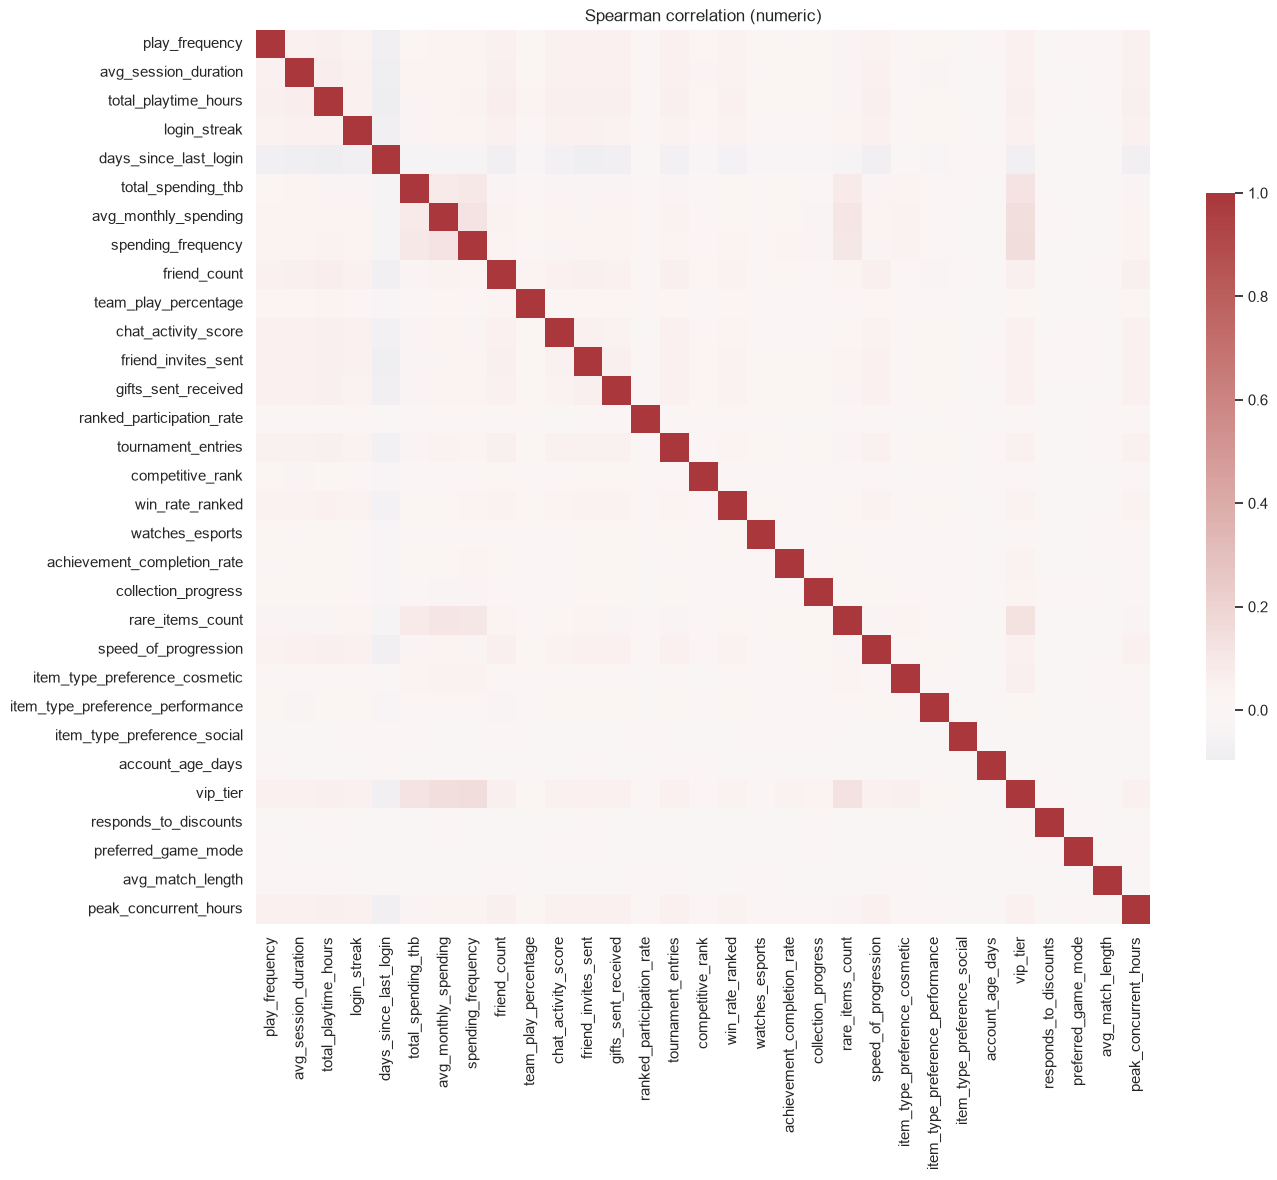

,level_0,level_1,rho,abs
243,spending_frequency,vip_tier,0.153377,0.153377
212,avg_monthly_spending,vip_tier,0.147472,0.147472
646,rare_items_count,vip_tier,0.127495,0.127495
193,avg_monthly_spending,spending_frequency,0.122704,0.122704
181,total_spending_thb,vip_tier,0.122572,0.122572
206,avg_monthly_spending,rare_items_count,0.113284,0.113284
237,spending_frequency,rare_items_count,0.106768,0.106768
162,total_spending_thb,spending_frequency,0.101715,0.101715
66,total_playtime_hours,days_since_last_login,-0.097318,0.097318
161,total_spending_thb,avg_monthly_spending,0.094442,0.094442


In [13]:
corr = train[[c for c in NUM if c not in NOISE_COLS]].corr(method="spearman")
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="vlag", center=0, square=True, cbar_kws={"shrink": .6})
plt.title("Spearman correlation (numeric)"); plt.tight_layout()
plt.savefig(FIG_DIR / "correlation.png", dpi=100); plt.show()
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
         .rename("rho").reset_index().assign(abs=lambda d: d.rho.abs())
         .sort_values("abs", ascending=False))
display(pairs.head(15))

## 8. Feature signal ranking (mutual information with target)

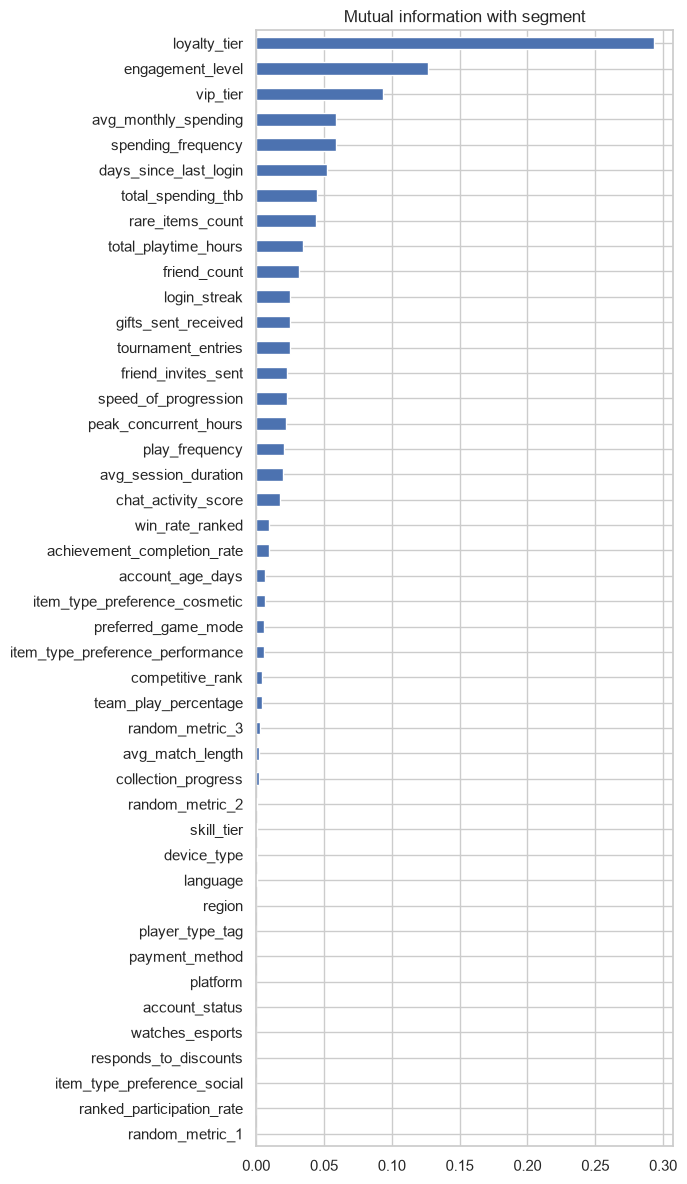

noise cols MI: {'random_metric_1': 0.0, 'random_metric_2': 0.0007, 'random_metric_3': 0.003}


In [14]:
from sklearn.feature_selection import mutual_info_classif
X = train[NUM + CAT_COLS].copy()
for c in CAT_COLS:
    X[c] = X[c].astype("category").cat.codes        # NaN -> -1
X[NUM] = X[NUM].fillna(X[NUM].median())
sample = X.sample(30000, random_state=SEED)
mi = mutual_info_classif(sample, train.loc[sample.index, TARGET],
                         discrete_features=[c in CAT_COLS for c in X.columns], random_state=SEED)
mi = pd.Series(mi, index=X.columns).sort_values(ascending=False)
ax = mi.plot.barh(figsize=(7, 12)); ax.invert_yaxis(); ax.set_title("Mutual information with segment")
plt.tight_layout(); plt.savefig(FIG_DIR / "mutual_info.png", dpi=100); plt.show()
print("noise cols MI:", mi[NOISE_COLS].round(4).to_dict())

## 9. Train vs test drift (adversarial validation)

In [15]:
import lightgbm as lgb
from sklearn.model_selection import cross_val_score
both = pd.concat([train[NUM + CAT_COLS].assign(is_test=0), test[NUM + CAT_COLS].assign(is_test=1)])
for c in CAT_COLS:
    both[c] = both[c].astype("category")
clf = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1, verbose=-1, random_state=SEED)
auc = cross_val_score(clf, both.drop(columns="is_test"), both["is_test"], cv=3, scoring="roc_auc")
print(f"adversarial AUC: {auc.mean():.4f}  (≈0.5 → train and test look alike)")

adversarial AUC: 0.5004  (≈0.5 → train and test look alike)


## 10. Quick reference baseline (raw features, LightGBM, 5-fold)

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, classification_report, confusion_matrix
Xb = train[[c for c in NUM if c not in NOISE_COLS] + CAT_COLS].copy()
for c in CAT_COLS:
    Xb[c] = Xb[c].astype("category")
y = train[TARGET]
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
base = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, verbose=-1, random_state=SEED)
oof = cross_val_predict(base, Xb, y, cv=skf)
print(f"OOF macro F1: {f1_score(y, oof, average='macro'):.4f}")
print(classification_report(y, oof, target_names=list(CLASS_NAMES.values()), digits=4))
display(pd.DataFrame(confusion_matrix(y, oof), index=order, columns=order))

OOF macro F1: 0.7485
              precision    recall  f1-score   support

      Casual     0.7875    0.8493    0.8172     40957
     Grinder     0.7431    0.7336    0.7383     26032
      Social     0.7291    0.6847    0.7062     21029
       Whale     0.7730    0.6958    0.7324     15982

    accuracy                         0.7635    104000
   macro avg     0.7582    0.7408    0.7485    104000
weighted avg     0.7624    0.7635    0.7620    104000



,Casual,Grinder,Social,Whale
Casual,34783,3665,2258,251
Grinder,5029,19096,767,1140
Social,3728,1027,14399,1875
Whale,627,1910,2324,11121


## 11. Findings & next steps

**Data** (updated Task 2 data, released 13 Nov)
- 104,000 train / 25,889 test rows, no duplicates, no ID overlap. Adversarial AUC = 0.50, so train and test come from the same distribution and CV should track the leaderboard.
- Classes: Casual 39.4% / Grinder 25.0% / Social 20.2% / Whale 15.4%. The imbalance is mild.
- Each column has about 7.7% missing (`region` 26%, `payment_method` 31%). 98% of rows have at least one gap, so dropping rows is not an option. Missingness looks **random** (rates differ by at most 0.8 points between segments), so missing-indicator features are unlikely to help.
- Unit oddities: `play_frequency` > 7 in 67% of rows (not really "days/week") and `peak_concurrent_hours` > 24 in 72%. Leave them as they are; tree models don't care about units.
- `player_id` carries no information about the segment in this version of the data. The original release leaked the label through ID blocks; see `archive/03_model_id_old_data.ipynb`.

**The segments form a 2×2 grid**
| | low spending | high spending |
|---|---|---|
| **low engagement** | Casual | Social |
| **high engagement** | Grinder | Whale |
- *Engagement axis* (Grinder/Whale about 1.4× Casual/Social): playtime, session length, play_frequency, login_streak, peak hours, tournaments, friend_count, invites, gifts, chat, progression speed, and inverse `days_since_last_login`.
- *Spending axis* (Social/Whale about 1.75× Casual/Grinder): total/monthly spending, spending_frequency, rare_items_count, vip_tier.
- Each feature on its own is weak (median ratios 1.4–1.8×), and features barely correlate with each other (max |ρ| ≈ 0.15). The signal is spread across many noisy columns, so **aggregating them** should help.
- The baseline confusion matrix matches this grid: most errors are Casual↔Grinder and Social↔Whale (engagement axis) and Casual↔Social (spending axis).

**Categoricals**
- `loyalty_tier` is a strong spending-axis proxy (Bronze → Casual/Grinder, Platinum/Diamond → Social/Whale). `engagement_level` is a strong engagement-axis proxy (Low → Casual/Social, Veteran → Grinder/Whale).
- `region, platform, device_type, payment_method, language, account_status, player_type_tag, skill_tier` show **no signal** (no category shifts a segment share by more than 0.01). Note that `player_type_tag` sounds relevant but is noise. These are candidates to drop, together with `random_metric_1/2/3`.

**Reference baseline:** LightGBM on raw features, 5-fold OOF **macro F1 = 0.7485**.

**Next:** `02_features` tests feature ideas; `03_model` tunes and compares six models.
